# Setup

In [1]:
# Load necessary packages
suppressPackageStartupMessages({
    library(DESeq2)
    library(ggplot2)
    library(glue)
    library(tidyverse)
    library(truncnorm)
    library(readr)
    library(tibble)
    library(glue)
    library(ggplot2)
    library(svglite)
    library(MASS)
    library(data.table)
})

In [2]:
# Define the plot size to use. 
options(repr.plot.width = 18, repr.plot.height = 6)

# Define the directory with the Simulated data. 
proc_dir = "run_simulation/results/for_real_comp"

# Load up size factors for normalizing all Real data. 
sf = read.csv("~/scratch/ch_diffbind/testing/output/MOR_test/NONO_DMSO_R/intermediates/normalization_factors.tsv", sep = "\t")

# Helper functions

In [3]:
summarize_background_counts = function(df, label, gene_col = "gene_id") {

    # Extract out the count columns. 
    count_cols = names(df)[sapply(df, is.numeric)]
    count_cols = setdiff(count_cols, gene_col)

    # Convert to matrix. 
    mat = as.matrix(df[, count_cols])

    # Calculate mean, variance, and dispersion terms. 
    gene_mean = rowMeans(mat, na.rm = TRUE)
    gene_var = apply(mat, 1, var, na.rm = TRUE)
    gene_disp = (gene_var - gene_mean) / gene_mean^2

    # Convert to dataframe. 
    df = data.frame(Dataset = label, gene_name = df[[gene_col]], mean_count = gene_mean, var_count = gene_var,
               disp_est = gene_disp, log10_mean = log10(gene_mean + 1), log10_var = log10(gene_var + 1),
               log10_disp = log10(pmax(gene_disp, 0) + 1e-8))
    return(df)
}

In [4]:
summarize_window_counts = function(df, label, gene_col = "gene_name", feature_col = "feature_type") {

    # Extract out the count columns. 
    count_cols = names(df)[sapply(df, is.numeric)]
    count_cols = setdiff(count_cols, c(gene_col, feature_col))

    # Convert to matrix. 
    mat = as.matrix(df[, count_cols])

    # Calculate mean and variance terms.
    window_mean = rowMeans(mat, na.rm = TRUE)
    window_var = apply(mat, 1, var, na.rm = TRUE)

    # Convert to dataframe.
    df = data.frame(Dataset = label, gene_name = df[[gene_col]], feature_type = df[[feature_col]],
               mean_count = window_mean, var_count = window_var, log10_mean = log10(window_mean + 1),
               log10_var = log10(window_var + 1))
    return(df)
}

In [5]:
make_binding_clip_df = function(df, Dataset, condition, rep, size_factor) {
    df = df %>%
        mutate(window_name = if ("window_name" %in% names(.)) window_name else paste(seq, start, end, sep = ":"),
            Dataset = Dataset, condition = condition, rep = rep, clip_raw = clip, clip = clip / size_factor,
            log10_clip = log10(clip + 1)) %>%
        dplyr::select(Dataset, condition, rep, clip_raw, clip, log10_clip, window_name)
    return(df)
}

# Comparisons

## background_counts

### Preprocessing

In [6]:
# Load the Simulated window counts.
Sim_background_counts = read.csv(glue("{proc_dir}/gene_counts/background_count.tsv"),
                                 sep = "\t")

# Fix column names. 
colnames(Sim_background_counts) = c("ctrl_IN_1", "ctrl_IP_1", "ctrl_IN_2", "ctrl_IP_2","trt_IN_1", "trt_IP_1", "trt_IN_2", "trt_IP_2", "gene_id")

In [7]:
# Load the Real window counts.
Real_background_counts = read.csv("../NONO_data/gene_wise_IN.tsv",
                                  sep = "\t")

# Filter out "multi-genes" (genes which represent overlapping regions between genes). 
Real_background_counts = Real_background_counts %>%
    filter(grepl("^ENSG[0-9]{11}\\.[0-9]+$", gene_id))

# Subset to just useful columns.
Real_background_counts = dplyr::select(Real_background_counts, c("gene_id","DMSO_IN_1", "DMSO_IN_2", "X10R_IN_1","X10R_IN_2"))

### Calculating metrics

In [8]:
# Collect summary data. 
Real_bg_summary = summarize_background_counts(Real_background_counts, "Real")
Sim_bg_summary  = summarize_background_counts(Sim_background_counts, "Sim")
bg_summary = bind_rows(Real_bg_summary, Sim_bg_summary)

### Plotting

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'
`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


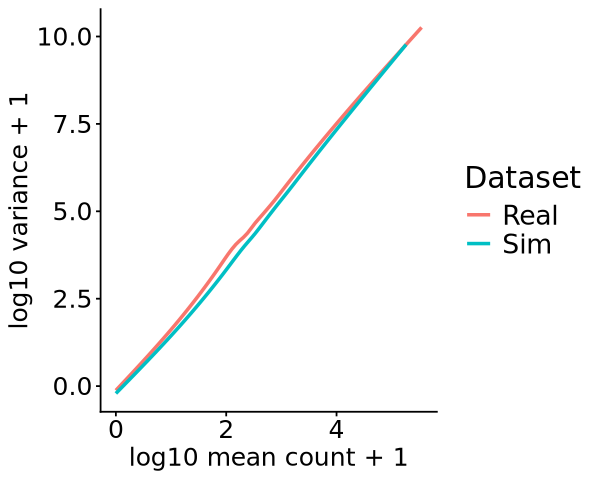

In [9]:
# Define the plot size to use.
options(repr.plot.width = 5, repr.plot.height = 4)

# plot the mean variance relationship. 
p = ggplot(bg_summary, aes(x = log10_mean, y = log10_var, color = Dataset)) +
        #geom_point(alpha = 0.15, size = 0.5) +
        geom_smooth(se = FALSE) +
        theme_classic() +
        labs(x = "log10 mean count + 1", y = "log10 variance + 1") + 
        theme(axis.title = element_text(size = 15), axis.text  = element_text(size = 15),
              legend.text = element_text(size = 16), legend.title = element_text(size = 18))

# Save plot. 
ggsave(filename = "real_comp_plots/background_variance_compact.svg", plot = p, device = svglite::svglite, width = 5, height = 4, units = "in")
p

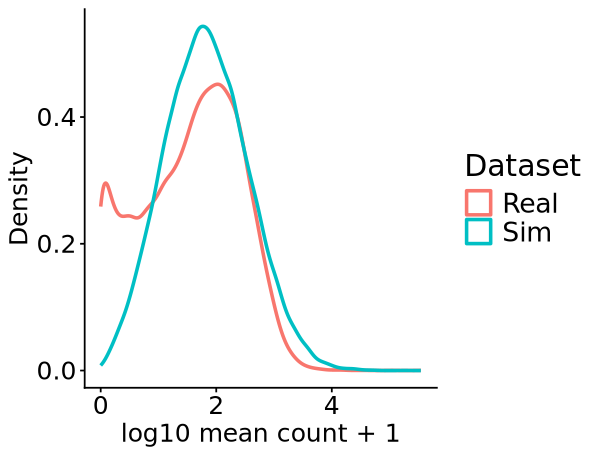

In [10]:
# Define the plot size to use.
options(repr.plot.width = 5, repr.plot.height = 3.8)

# Plot the mean count relationship. 
p = ggplot(bg_summary, aes(x = log10_mean, color = Dataset)) +
        geom_density(linewidth = 1) +
        theme_classic() +
        labs(x = "log10 mean count + 1", y = "Density") + 
        theme(axis.title = element_text(size = 15), axis.text  = element_text(size = 15),
              legend.text = element_text(size = 16), legend.title = element_text(size = 18))

# Save plot. 
ggsave(filename = "real_comp_plots/background_density_compact.svg", plot = p, device = svglite::svglite, width = 5, height = 3.8, units = "in")
p

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'
`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


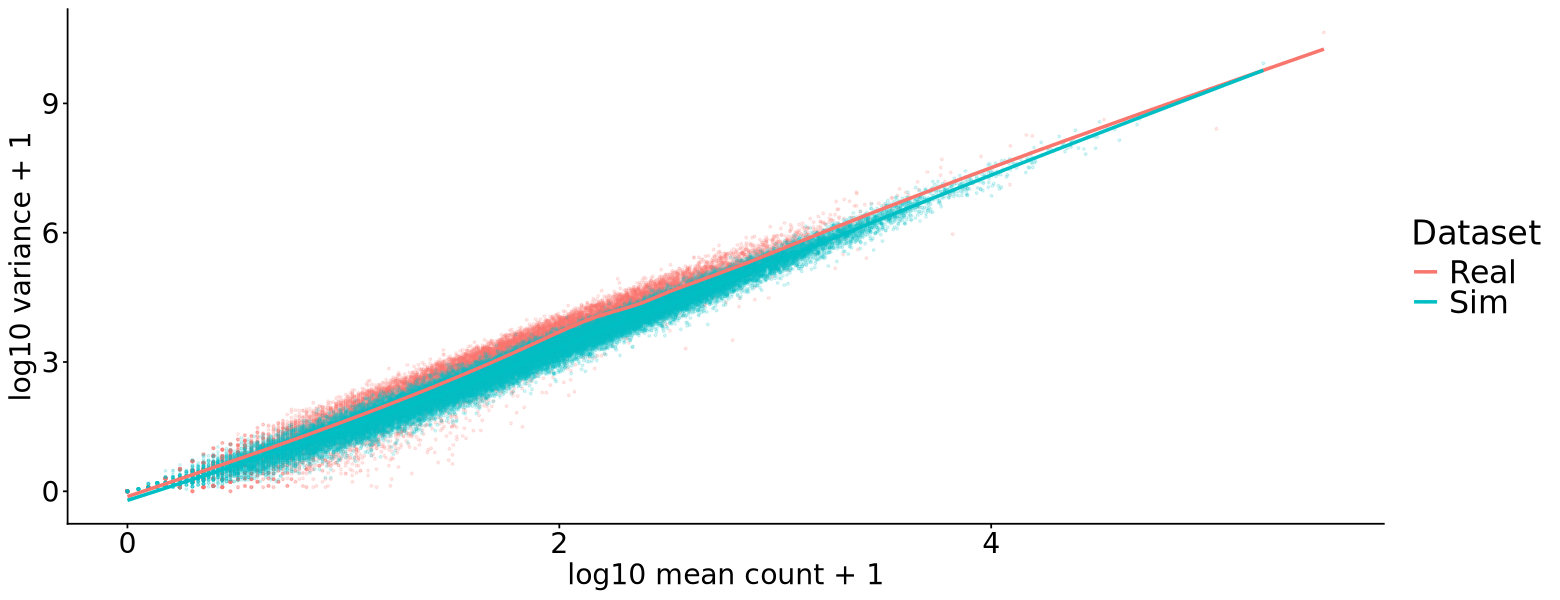

In [11]:
# Define the plot size to use.
options(repr.plot.width = 13, repr.plot.height = 5)

# plot the mean variance relationship. 
p = ggplot(bg_summary, aes(x = log10_mean, y = log10_var, color = Dataset)) +
        geom_point(alpha = 0.15, size = 0.5) +
        geom_smooth(se = FALSE) +
        theme_classic() +
        labs(x = "log10 mean count + 1", y = "log10 variance + 1") + 
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20))

# Save plot. 
ggsave(filename = "real_comp_plots/background_variance_broad.png", plot = p, width = 13, height = 5, units = "in", dpi = 400)
p

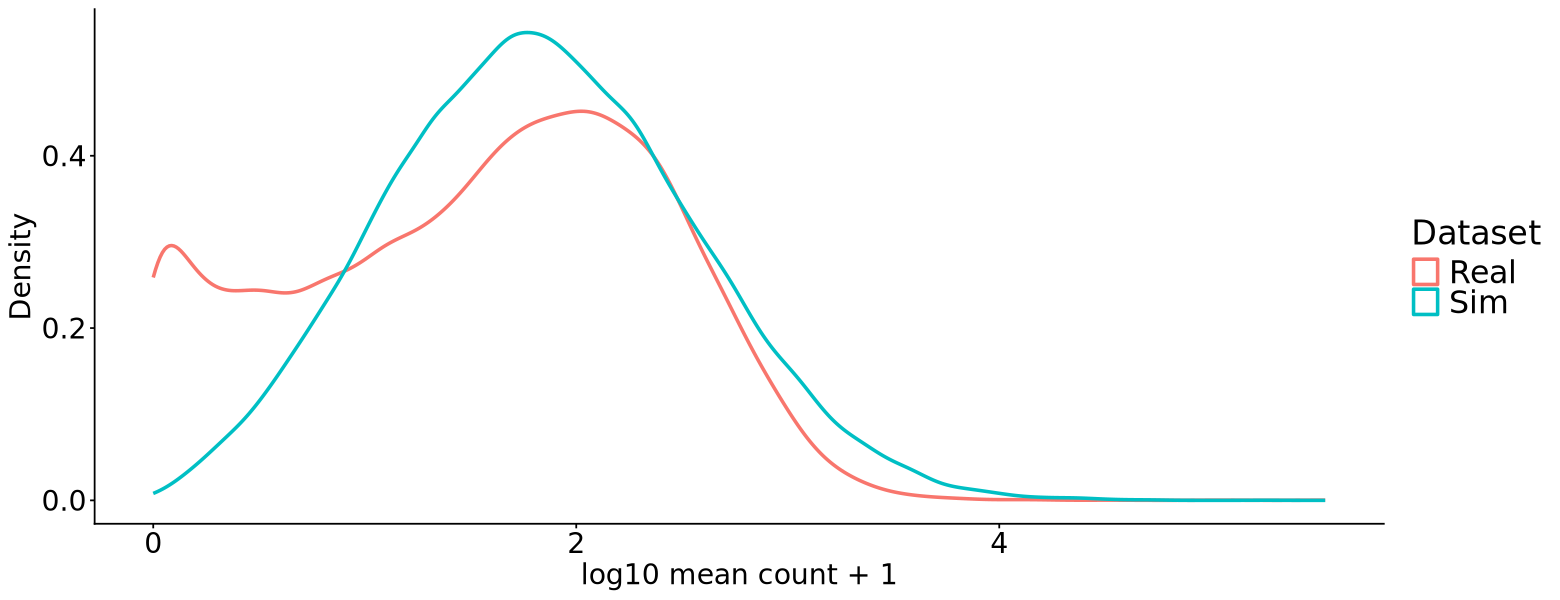

In [12]:
# Define the plot size to use.
options(repr.plot.width = 13, repr.plot.height = 5)

# Plot the mean count relationship. 
p = ggplot(bg_summary, aes(x = log10_mean, color = Dataset)) +
        geom_density(linewidth = 1) +
        theme_classic() +
        labs(x = "log10 mean count + 1", y = "Density") + 
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20))

# Save plot.
ggsave(filename = "real_comp_plots/background_density_broad.png", plot = p, width = 13, height = 5, units = "in", dpi = 400)
p

## Window_counts

### Preprocessing

In [13]:
# Load the Simulated window counts. 
Sim_window_counts = read.csv(glue("{proc_dir}/window_counts/window_counts.tsv"),
                             sep = "\t")
# Select only meaningful columns. 
Sim_window_counts = dplyr::select(Sim_window_counts, c("gene_name", "feature_type", "feature_id", "control_IN_1", "control_IN_2"))

# Define size factors. 
ex_size_factors = c(control_IN_1 = 0.95, control_IN_2 = 2.15)

# Create a copy.
Sim_window_counts_norm = copy(Sim_window_counts)

# Divide each column by its size factor. 
Sim_window_counts_norm[, names(ex_size_factors)] = sweep(Sim_window_counts[, names(ex_size_factors)], 2, ex_size_factors, "/")

In [14]:
# Load the Real window counts. 
Real_window_counts = read.csv("~/scratch/new_skipper_test/testing/results/NONO_skipper_updated/output/secondary_results/counts/genome/tables/DMSO.tsv.gz",
                             sep = "\t")

# Load up annotation data. 
anno = read.csv("/tscc/lustre/ddn/scratch/kflanagan/new_skipper_annotations/G49.GTEx.Prostate.tiled_partition.features.tsv.gz",
               sep = "\t")

# Subset annotation data to just the columns of interest. 
anno = dplyr::select(anno, c(base_feature_id, feature_type_top, gene_name))

# Add annotation to to window count data. 
Real_window_counts = cbind(anno, Real_window_counts)
Real_window_counts = dplyr::select(Real_window_counts, c(gene_name, feature_type_top, base_feature_id, DMSO_IN_1, DMSO_IN_2))
Real_window_counts$base_feature_id = as.character(Real_window_counts$base_feature_id)

# Remove windows outside of intronic/exonic regions. 
Real_window_counts = subset(Real_window_counts, !feature_type_top %in% c("UTR3", "UTR5", "EXON_PSEUDO", "PRIMIRNA"))

# Find count columns that have size factors.
count_cols = intersect(colnames(Real_window_counts), sf$Sample)

# Pull out the size factors in the same order as count_cols.
sf_vec = sf$SizeFactor[match(count_cols, sf$Sample)]

# Create a copy.
Real_window_counts_norm = copy(Real_window_counts)

# Divide each column by its size factor.
Real_window_counts_norm[, count_cols] = sweep(Real_window_counts[, count_cols], 2, sf_vec, "/")

### Calculating metrics

In [15]:
Real_win_summary = summarize_window_counts(Real_window_counts_norm, "Real", feature_col = "base_feature_id")
Sim_win_summary  = summarize_window_counts(Sim_window_counts_norm, "Sim")
win_summary = bind_rows(Real_win_summary, Sim_win_summary)

### Plotting

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'
`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


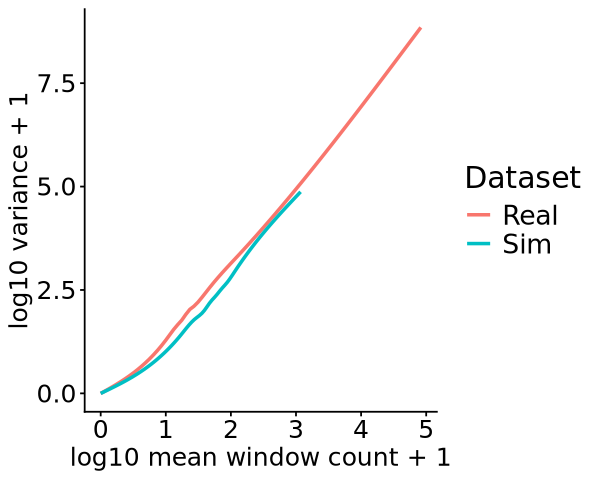

In [16]:
# Define the plot size to use.
options(repr.plot.width = 5, repr.plot.height = 4)

p = ggplot(win_summary, aes(x = log10_mean, y = log10_var, color = Dataset)) +
        #geom_point(alpha = 0.1, size = 0.4) +
        geom_smooth(se = FALSE) +
        theme_classic() +
        labs(x = "log10 mean window count + 1", y = "log10 variance + 1") +
        theme(axis.title = element_text(size = 15), axis.text  = element_text(size = 15),
              legend.text = element_text(size = 16), legend.title = element_text(size = 18))

# Save plot. 
ggsave(filename = "real_comp_plots/window_variance_compact.svg", plot = p, device = svglite::svglite, width = 5, height = 4, units = "in")
p

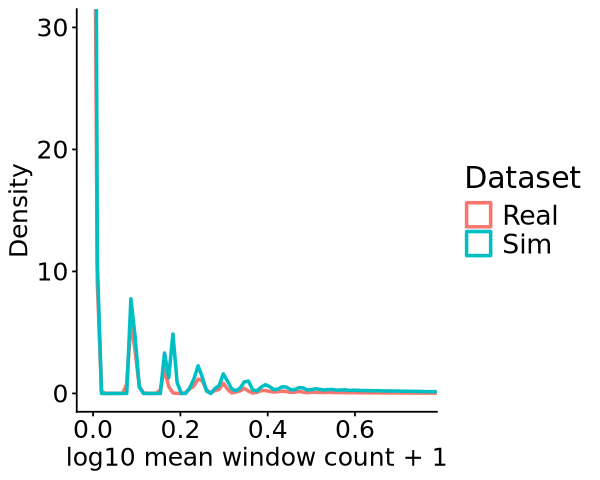

In [22]:
# Define the plot size to use.
options(repr.plot.width = 5, repr.plot.height = 4)

p = ggplot(win_summary, aes(x = log10_mean, color = Dataset)) +
        geom_density(linewidth = 1) +
        coord_cartesian(xlim = c(0, 0.75), ylim = c(0, 30)) +
        theme_classic() +
        labs(x = "log10 mean window count + 1", y = "Density") +
        theme(axis.title = element_text(size = 15), axis.text  = element_text(size = 15),
              legend.text = element_text(size = 16), legend.title = element_text(size = 18))

# Save plot. 
ggsave(filename = "real_comp_plots/window_density_compact.svg", plot = p, device = svglite::svglite, width = 5, height = 4, units = "in")
p

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'
`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


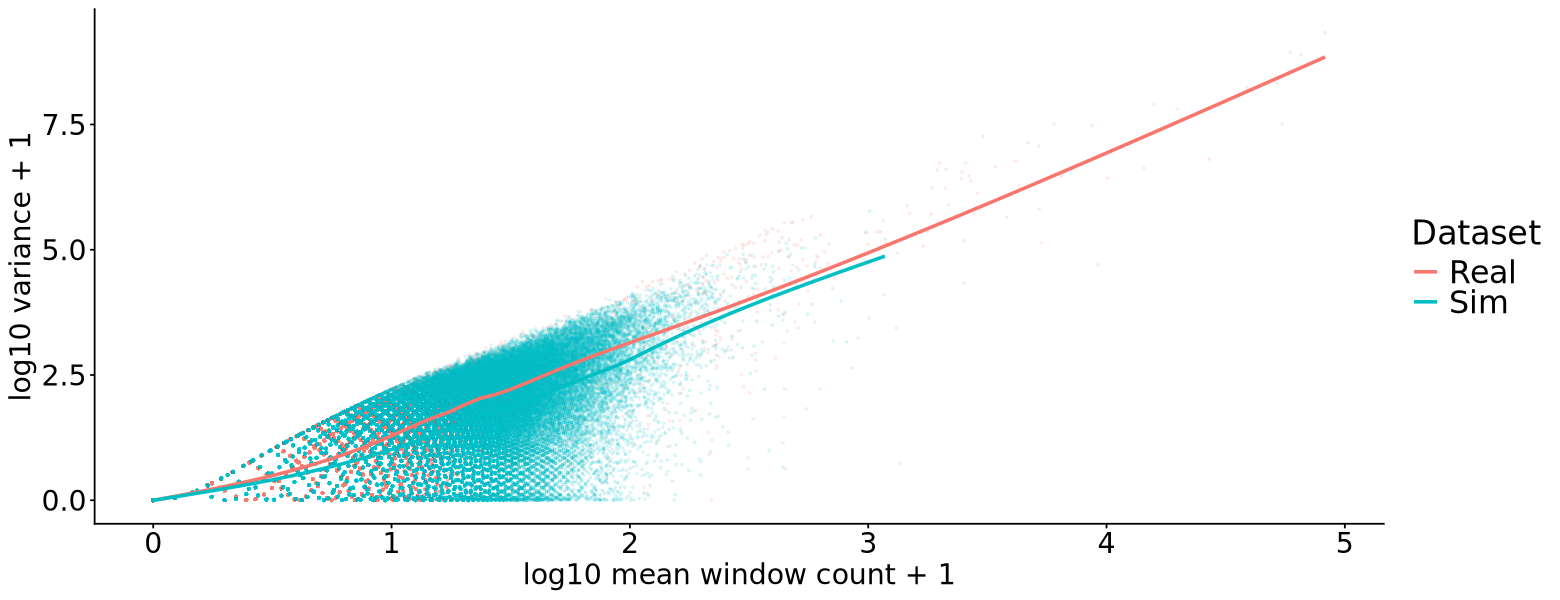

In [18]:
# Define the plot size to use.
options(repr.plot.width = 13, repr.plot.height = 5)

# Plot the mean count relationship. 
p = ggplot(win_summary, aes(x = log10_mean, y = log10_var, color = Dataset)) +
        geom_point(alpha = 0.1, size = 0.4) +
        geom_smooth(se = FALSE) +
        theme_classic() +
        labs(x = "log10 mean window count + 1", y = "log10 variance + 1") +
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20))

# Save plot.
ggsave(filename = "real_comp_plots/window_variance_broad.png", plot = p, width = 13, height = 5, units = "in", dpi = 400)
p

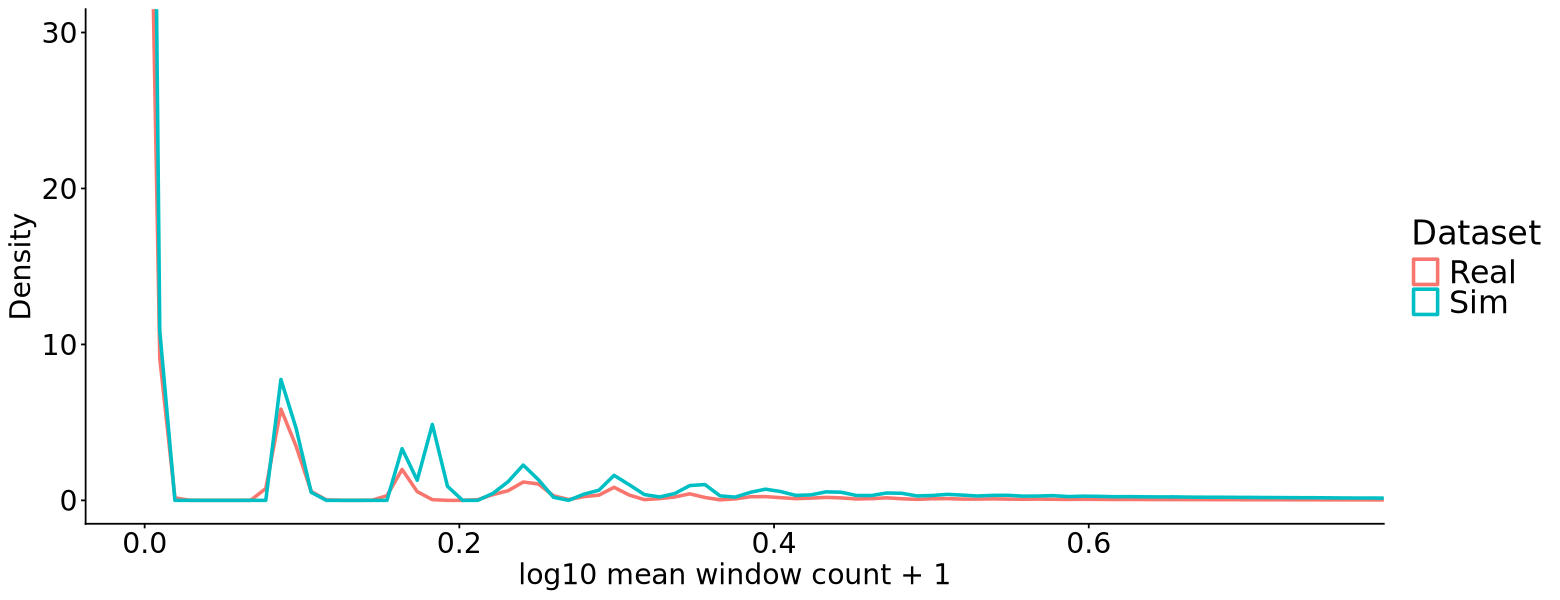

In [53]:
# Define the plot size to use.
options(repr.plot.width = 13, repr.plot.height = 5)

# plot the mean variance relationship. 
p = ggplot(win_summary, aes(x = log10_mean, color = Dataset)) +
        geom_density(linewidth = 1) +
        coord_cartesian(xlim = c(0, 0.75), ylim = c(0, 30)) +
        theme_classic() +
        labs(x = "log10 mean window count + 1", y = "Density") +
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20))

# Save plot. 
ggsave(filename = "real_comp_plots/window_density_broad.svg", plot = p, device = svglite::svglite, width = 13, height = 5, units = "in")
p

## Binding counts

### Pre-processing

In [24]:
# Load the Real and Simulated counts at binding windows found by Skipper. 
Sim_binding_windows_ctrl_1 = read.csv(glue("{proc_dir}/skipper/enriched_windows/control.control_IP_1.enriched_windows.tsv"),
                               sep = "\t")
Sim_binding_windows_ctrl_2 = read.csv(glue("{proc_dir}/skipper/enriched_windows/control.control_IP_2.enriched_windows.tsv"),
                               sep = "\t")
Sim_binding_windows_trt_1 = read.csv(glue("{proc_dir}/skipper/enriched_windows/treatment.treatment_IP_1.enriched_windows.tsv"),
                               sep = "\t")
Sim_binding_windows_trt_2 = read.csv(glue("{proc_dir}/skipper/enriched_windows/treatment.treatment_IP_2.enriched_windows.tsv"),
                               sep = "\t")
Real_binding_windows_ctrl_1 = read.csv(glue("~/scratch/new_skipper_test/testing/results/NONO_skipper_updated/output/secondary_results/enriched_windows/DMSO.DMSO_IP_1.enriched_windows.tsv.gz"),
                             sep = "\t")
Real_binding_windows_ctrl_2 = read.csv(glue("~/scratch/new_skipper_test/testing/results/NONO_skipper_updated/output/secondary_results/enriched_windows/DMSO.DMSO_IP_2.enriched_windows.tsv.gz"),
                             sep = "\t")
Real_binding_windows_trt_1 = read.csv(glue("~/scratch/new_skipper_test/testing/results/NONO_skipper_updated/output/secondary_results/enriched_windows/10R.10R_IP_1.enriched_windows.tsv.gz"),
                             sep = "\t")
Real_binding_windows_trt_2 = read.csv(glue("~/scratch/new_skipper_test/testing/results/NONO_skipper_updated/output/secondary_results/enriched_windows/10R.10R_IP_2.enriched_windows.tsv.gz"),
                             sep = "\t")

In [25]:
# Fix the naming scheme on window name. 
Real_binding_windows_ctrl_1$window_name = Real_binding_windows_ctrl_1$name
Real_binding_windows_ctrl_2$window_name = Real_binding_windows_ctrl_2$name
Real_binding_windows_trt_1$window_name = Real_binding_windows_trt_1$name
Real_binding_windows_trt_2$window_name = Real_binding_windows_trt_2$name

### Calculating metrics

In [26]:
# Load up size factors
ex_size_factors = c(ctrl_IP_1 = 1.2, ctrl_IP_2 = 1.75, trt_IP_1  = 0.70, trt_IP_2  = 1.30)

binding_clip = bind_rows(
    make_binding_clip_df(Sim_binding_windows_ctrl_1, "Sim", "control", "rep1", ex_size_factors["ctrl_IP_1"]),
    make_binding_clip_df(Sim_binding_windows_ctrl_2, "Sim", "control", "rep2", ex_size_factors["ctrl_IP_2"]),
    make_binding_clip_df(Sim_binding_windows_trt_1, "Sim", "treatment", "rep1", ex_size_factors["trt_IP_1"]),
    make_binding_clip_df(Sim_binding_windows_trt_2, "Sim", "treatment", "rep2", ex_size_factors["trt_IP_2"]),
    make_binding_clip_df(Real_binding_windows_ctrl_1, "Real", "control", "rep1", sf$SizeFactor[match("DMSO_IP_1", sf$Sample)]),
    make_binding_clip_df(Real_binding_windows_ctrl_2, "Real", "control", "rep2", sf$SizeFactor[match("DMSO_IP_2", sf$Sample)]),
    make_binding_clip_df(Real_binding_windows_trt_1, "Real", "treatment", "rep1", sf$SizeFactor[match("X10R_IP_1", sf$Sample)]),
    make_binding_clip_df(Real_binding_windows_trt_2, "Real", "treatment", "rep2", sf$SizeFactor[match("X10R_IP_2", sf$Sample)])
)

In [28]:
# Calculate replicate variance metrics. 
replicate_variance = binding_clip %>%
    pivot_wider(id_cols = c(Dataset, condition, window_name), names_from = rep, values_from = clip) %>%
    filter(!is.na(rep1), !is.na(rep2)) %>%
    mutate(mean_clip = (rep1 + rep2) / 2, abs_log2_rep_fc = abs(log2((rep1 + 1) / (rep2 + 1))),
           sd_clip = abs(rep1 - rep2) / sqrt(2), cv_clip = sd_clip / pmax(mean_clip, 1),
           log10_mean_clip = log10(mean_clip + 1), log10_cv_clip = log10(cv_clip + 1e-4))

In [29]:
# Calculate trend line (robust to outliers). 
trend_df = replicate_variance %>%
    filter(is.finite(log10_mean_clip), is.finite(abs_log2_rep_fc)) %>%
    group_by(Dataset, condition) %>%
    mutate(mean_bin = cut(log10_mean_clip, breaks = quantile(log10_mean_clip, probs = seq(0, 1, 0.05), na.rm = TRUE),
                          include.lowest = TRUE)) %>%
    group_by(Dataset, condition, mean_bin) %>%
    summarize(bin_x = median(log10_mean_clip, na.rm = TRUE), bin_y = median(abs_log2_rep_fc, na.rm = TRUE),.groups = "drop")

### Plotting

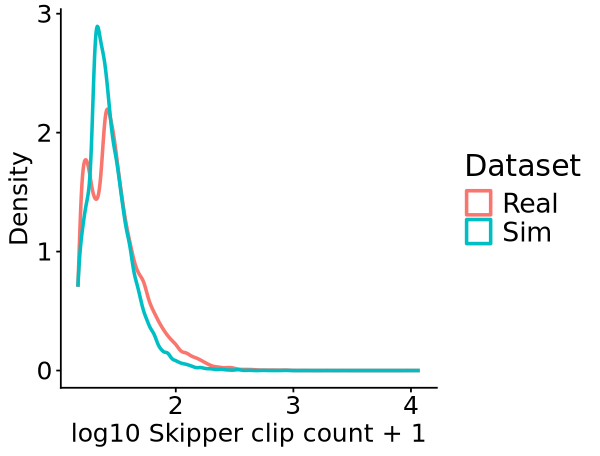

In [46]:
# Define the plot size to use.
options(repr.plot.width = 5, repr.plot.height = 3.8)

p = binding_clip %>%
    filter(condition == "control") %>%
    ggplot(aes(x = log10_clip, color = Dataset)) +
    geom_density(linewidth = 1) +
    theme_classic() +
    labs(x = "log10 Skipper clip count + 1", y = "Density") +
    theme(
        axis.title = element_text(size = 15),
        axis.text = element_text(size = 15),
        legend.text = element_text(size = 16),
        legend.title = element_text(size = 18)
    )

# Save plot. 
ggsave(filename = "real_comp_plots/skipper_density_compact.svg", plot = p, device = svglite::svglite, width = 5, height = 3.8, units = "in")
p

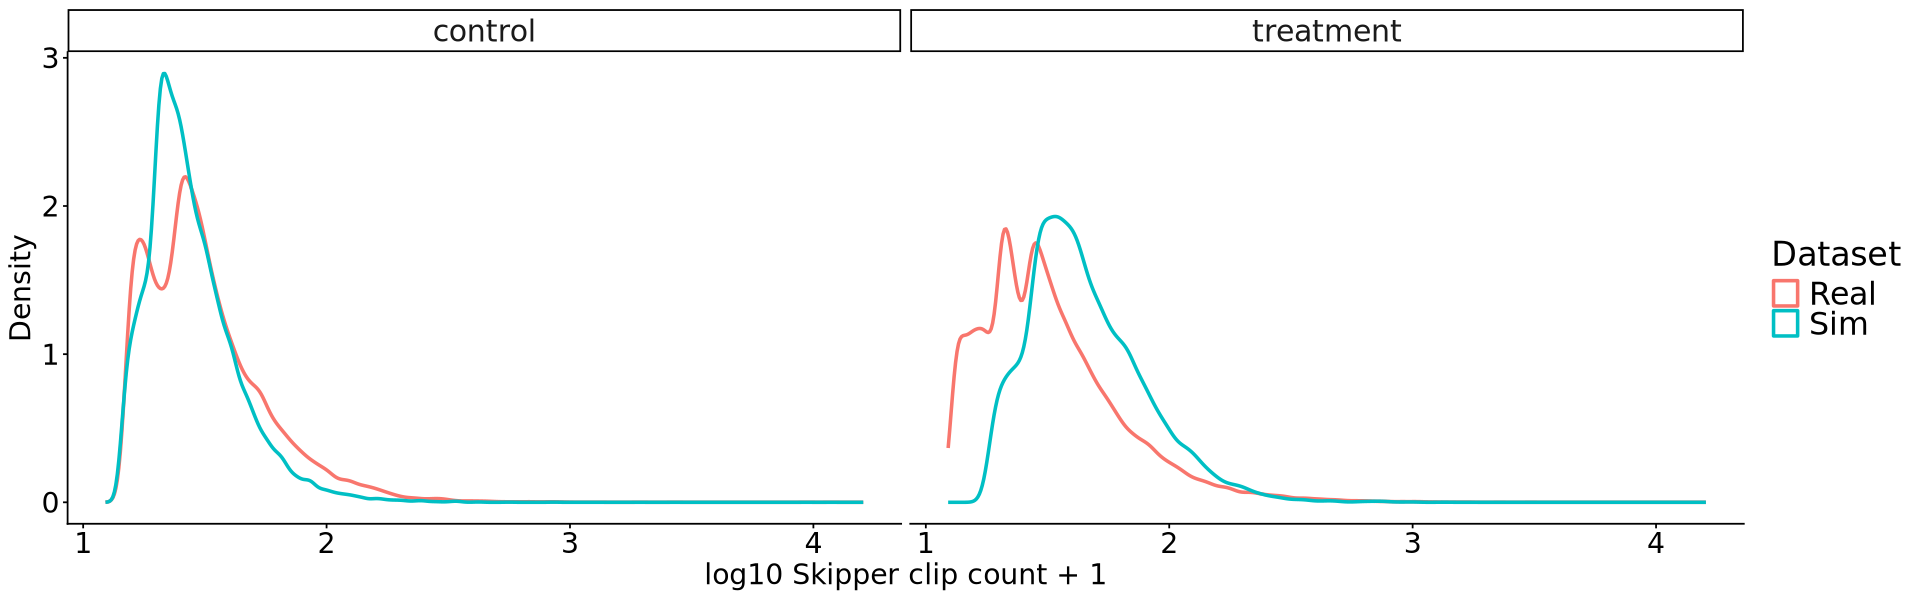

In [51]:
# Define the plot size to use.
options(repr.plot.width = 16, repr.plot.height = 5)

p = ggplot(binding_clip, aes(x = log10_clip, color = Dataset)) +
        geom_density(linewidth = 1) +
        facet_wrap(~ condition) +
        theme_classic() +
        labs(x = "log10 Skipper clip count + 1", y = "Density") + 
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20),
              strip.text = element_text(size = 18))

ggsave(filename = "real_comp_plots/skipper_density_broad.svg", plot = p, device = svglite::svglite, width = 16, height = 5, units = "in")
p

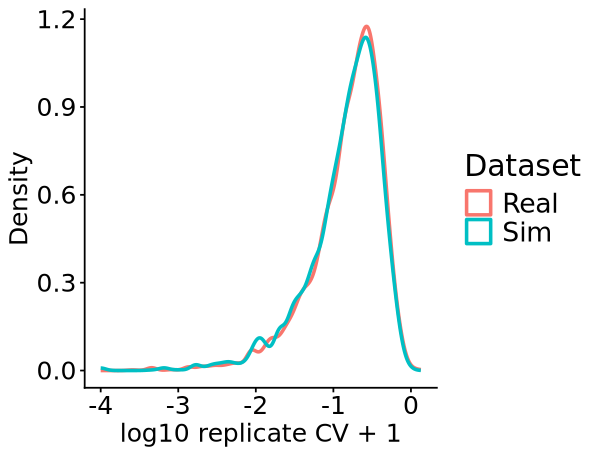

In [47]:
# Define the plot size to use.
options(repr.plot.width = 5, repr.plot.height = 3.8)

p = replicate_variance %>%
    filter(condition == "control") %>%
    ggplot(aes(x = log10_cv_clip, color = Dataset)) +
    geom_density(linewidth = 1) +
        theme_classic() +
        labs(x = "log10 replicate CV + 1", y = "Density") +
        theme(
            axis.title = element_text(size = 15),
            axis.text = element_text(size = 15),
            legend.text = element_text(size = 16),
            legend.title = element_text(size = 18)
        )

ggsave(filename = "real_comp_plots/skipper_CV_compact.svg", plot = p, device = svglite::svglite, width = 5, height = 3.8, units = "in")
p

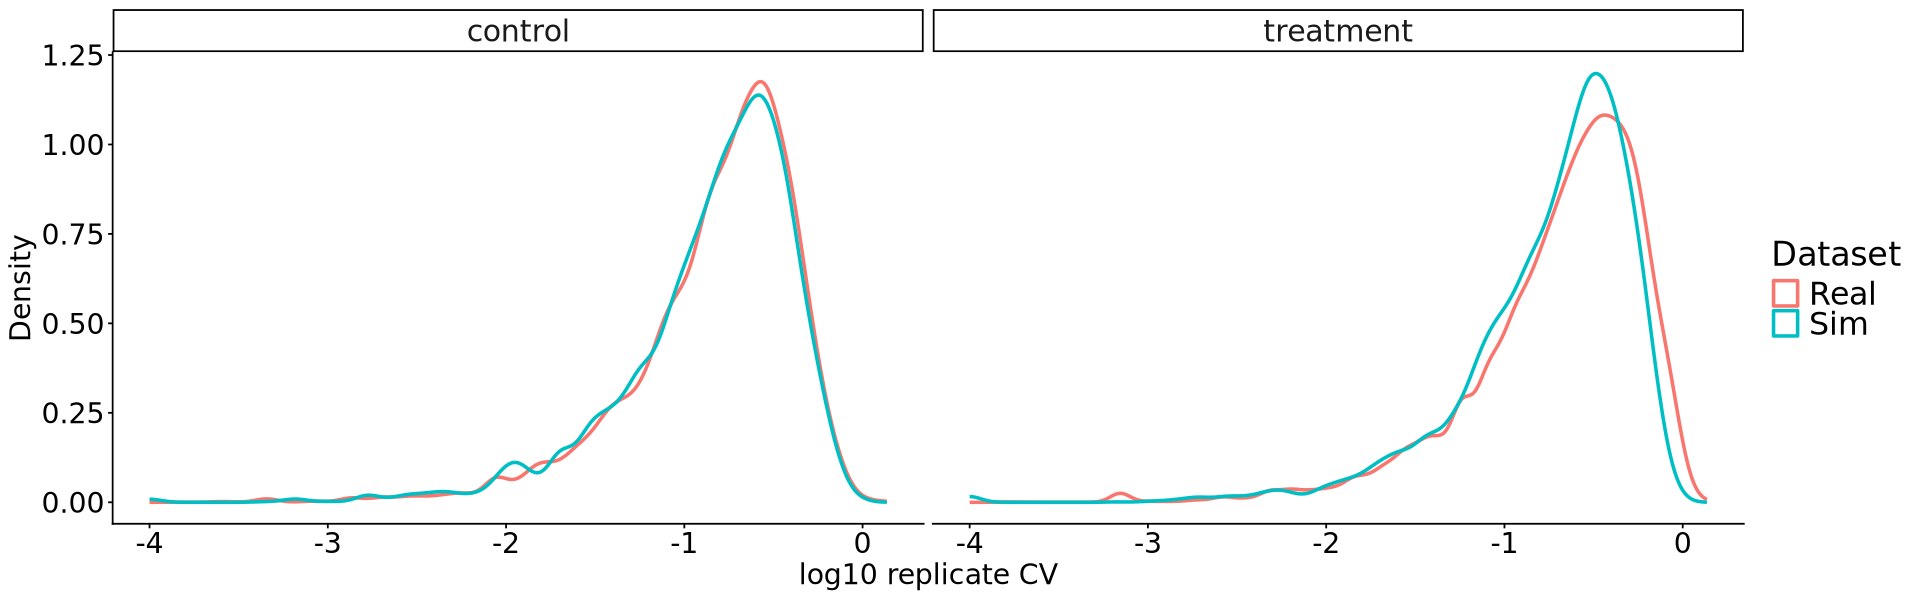

In [48]:
# Define the plot size to use.
options(repr.plot.width = 16, repr.plot.height = 5)

p = ggplot(replicate_variance, aes(x = log10_cv_clip, color = Dataset)) +
        geom_density(linewidth = 1) +
        facet_wrap(~ condition) +
        theme_classic() +
        labs(x = "log10 replicate CV", y = "Density") +
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20),
              strip.text = element_text(size = 18))

ggsave(filename = "real_comp_plots/skipper_CV_broad.svg", plot = p, device = svglite::svglite, width = 16, height = 5, units = "in")
p

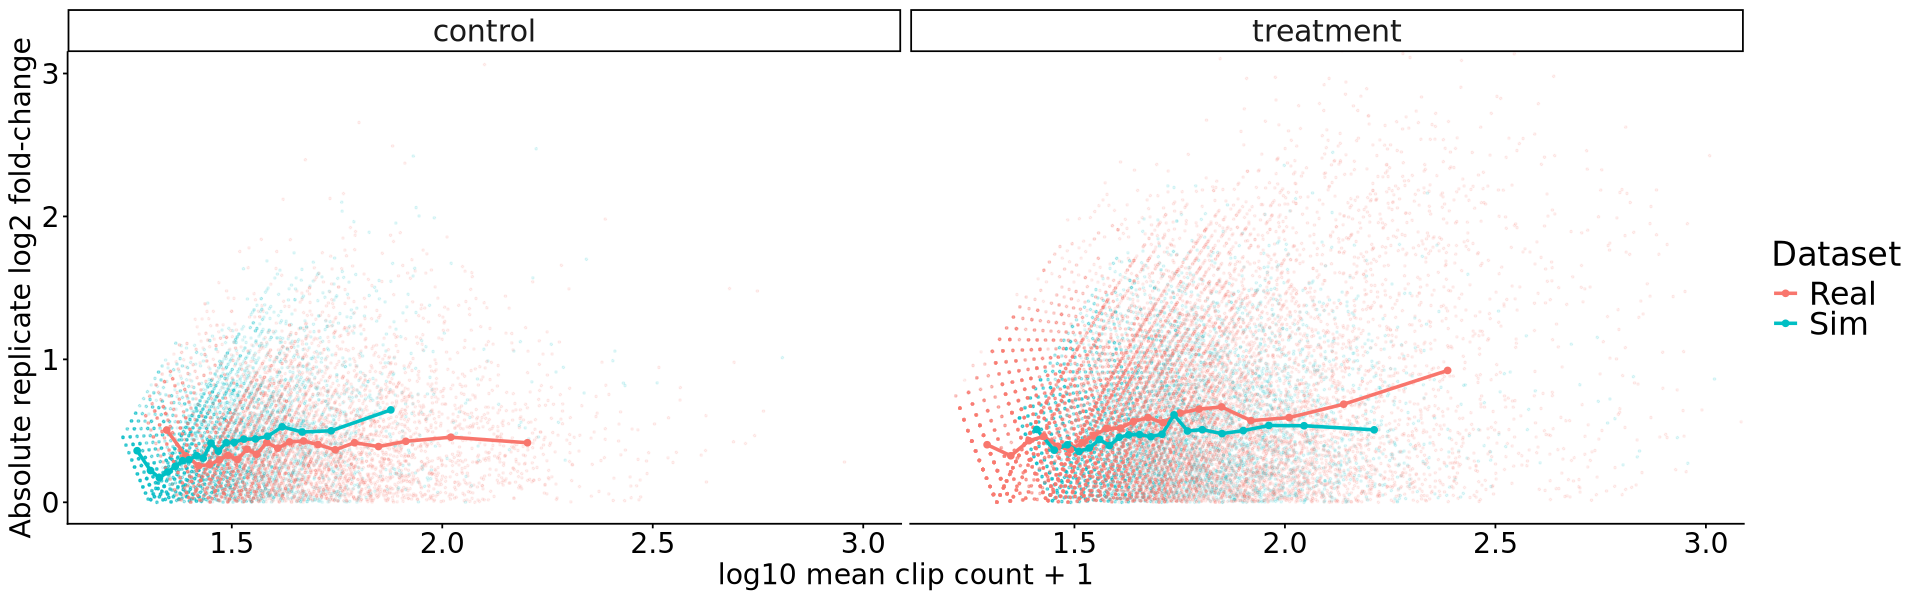

In [49]:
# Define the plot size to use.
options(repr.plot.width = 16, repr.plot.height = 5)

p = ggplot(replicate_variance, aes(x = log10_mean_clip, y = abs_log2_rep_fc, color = Dataset)) +
        geom_point(alpha = 0.10, size = 0.4) +
        geom_line(data = trend_df, aes(x = bin_x, y = bin_y, color = Dataset), linewidth = 1) +
        geom_point(data = trend_df, aes(x = bin_x, y = bin_y, color = Dataset), size = 1.5) +
        coord_cartesian(xlim = c(1.2, 3), ylim = c(0, 3)) +
        facet_wrap(~ condition) +
        theme_classic() +
        labs(x = "log10 mean clip count + 1", y = "Absolute replicate log2 fold-change") +
        theme(axis.title = element_text(size = 17), axis.text  = element_text(size = 17),
              legend.text = element_text(size = 19), legend.title = element_text(size = 20),
              strip.text = element_text(size = 18))

ggsave(filename = "real_comp_plots/skipper_mean_var_broad.png", plot = p, width = 16, height = 5, units = "in")
p

In [17]:
# Summarize all variance terms into a neat table. 
variance_summary = replicate_variance %>%
    group_by(Dataset, condition) %>%
    summarize(n_shared_windows = n(), median_abs_log2_rep_fc = median(abs_log2_rep_fc, na.rm = TRUE),
              mean_abs_log2_rep_fc = mean(abs_log2_rep_fc, na.rm = TRUE),
              q75_abs_log2_rep_fc = quantile(abs_log2_rep_fc, 0.75, na.rm = TRUE),
              q90_abs_log2_rep_fc = quantile(abs_log2_rep_fc, 0.90, na.rm = TRUE),
              median_cv = median(cv_clip, na.rm = TRUE), mean_cv = mean(cv_clip, na.rm = TRUE),
              median_mean_clip = median(mean_clip, na.rm = TRUE), .groups = "drop")

variance_summary

Dataset,condition,n_shared_windows,median_abs_log2_rep_fc,mean_abs_log2_rep_fc,q75_abs_log2_rep_fc,q90_abs_log2_rep_fc,median_cv,mean_cv,median_mean_clip
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Real,control,5909,0.3728184,0.4435035,0.6185169,0.8920916,0.1865948,0.2170326,38.44772
Real,treatment,16725,0.5108700,0.6321525,0.8984940,1.3236025,0.2577067,0.3006460,41.07156
Sim,control,4922,0.3507465,0.4204669,0.5945305,0.8534160,0.1773451,0.2079925,27.72619
Sim,treatment,6289,0.4654157,0.5375502,0.7732721,1.0964989,0.2321843,0.2604616,45.54945
